# Practical 9: K-Nearest Neighbours

## Aim
KNN classification of Iris with scaling, error rate against K, best K and decision regions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [2]:
iris = load_iris(as_frame=True)
df = iris.data.copy()
df["species"] = iris.target_names[iris.target]
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
df.to_csv("iris.csv", index=False)

In [3]:
print(df.head())
df.info()
print(df.describe().round(4))
print(df.groupby("species").mean().round(3))

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
       sepal_length  sepal_width  petal_length  petal_width
count      150.0000     150.0000      150.0000     150.0000
mean         5.8433       3.0573        3.7580       1

In [4]:
X, y = df.iloc[:, :4].values, df["species"].values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

In [5]:
knn = KNeighborsClassifier(n_neighbors=5).fit(X_tr_s, y_tr)
pred = knn.predict(X_te_s)
cm = confusion_matrix(y_te, pred)
print("\nConfusion matrix (K=5):")
print(cm)
print("Accuracy: %.4f" % accuracy_score(y_te, pred))
print(classification_report(y_te, pred))


Confusion matrix (K=5):
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]
Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [6]:
errors = []
for k in range(1, 31):
    p = KNeighborsClassifier(n_neighbors=k).fit(X_tr_s, y_tr).predict(X_te_s)
    errors.append(np.mean(p != y_te))
    print("K = %2d  error = %.4f" % (k, errors[-1]))

K =  1  error = 0.0333
K =  2  error = 0.0667
K =  3  error = 0.0667
K =  4  error = 0.0667
K =  5  error = 0.0667
K =  6  error = 0.0667
K =  7  error = 0.0333
K =  8  error = 0.0667
K =  9  error = 0.0333
K = 10  error = 0.0333
K = 11  error = 0.0333
K = 12  error = 0.0333
K = 13  error = 0.0333
K = 14  error = 0.0333
K = 15  error = 0.0333
K = 16  error = 0.0333
K = 17  error = 0.0333
K = 18  error = 0.0333
K = 19  error = 0.0333
K = 20  error = 0.0333
K = 21  error = 0.0333
K = 22  error = 0.0667
K = 23  error = 0.0667
K = 24  error = 0.1000
K = 25  error = 0.1000
K = 26  error = 0.1333
K = 27  error = 0.1333
K = 28  error = 0.1333
K = 29  error = 0.1333
K = 30  error = 0.1333


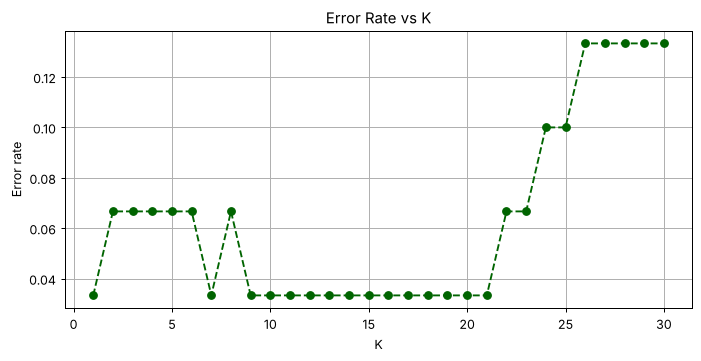

In [7]:
plt.figure(figsize=(9, 4))
plt.plot(range(1, 31), errors, "o--", color="darkgreen")
plt.title("Error Rate vs K")
plt.xlabel("K")
plt.ylabel("Error rate")
plt.grid(True)
plt.show()

In [8]:
low = min(errors)
best = [k for k, e in enumerate(errors, 1) if e == low and k % 2 == 1]
best_k = best[len(best) // 2]
print("\nLowest error: %.4f" % low)
print("Odd K values with that error:", best)
print("Chosen K:", best_k)


Lowest error: 0.0333
Odd K values with that error: [1, 7, 9, 11, 13, 15, 17, 19, 21]
Chosen K: 13


In [9]:
final = KNeighborsClassifier(n_neighbors=best_k).fit(X_tr_s, y_tr)
print("Accuracy with K=%d: %.4f" % (best_k, final.score(X_te_s, y_te)))

Accuracy with K=13: 0.9667


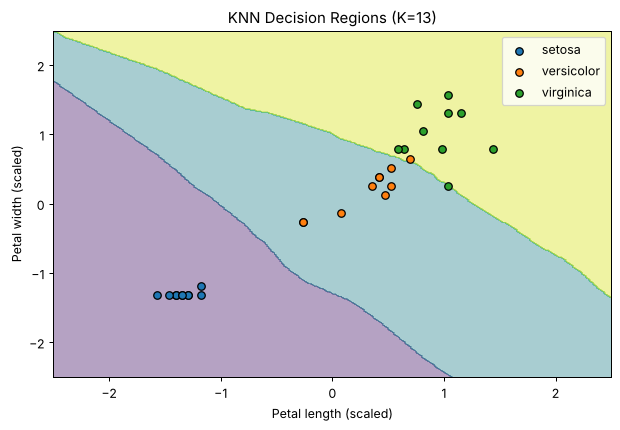

In [10]:
cols = [2, 3]
sc2 = StandardScaler().fit(X_tr[:, cols])
m2 = KNeighborsClassifier(n_neighbors=best_k).fit(sc2.transform(X_tr[:, cols]), y_tr)
xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 300), np.linspace(-2.5, 2.5, 300))
zz = m2.predict(np.c_[xx.ravel(), yy.ravel()])
names = list(m2.classes_)
zz = np.array([names.index(v) for v in zz]).reshape(xx.shape)
plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, zz, alpha=0.4)
pts = sc2.transform(X_te[:, cols])
for n in names:
    plt.scatter(pts[y_te == n, 0], pts[y_te == n, 1], edgecolor="black", label=n)
plt.legend()
plt.title("KNN Decision Regions (K=%d)" % best_k)
plt.xlabel("Petal length (scaled)")
plt.ylabel("Petal width (scaled)")
plt.show()

In [11]:
print("\nResult: K=5 gives 93.33% accuracy; the chosen K gives the final accuracy printed above.")


Result: K=5 gives 93.33% accuracy; the chosen K gives the final accuracy printed above.
